# Evidential classification of synthetic DNA-like sequences
This self-contained CPU example classifies **synthetic sequence compositions**, with disjoint training, validation and test sets. It uses base-frequency features and the package's evidential neural classifier. The task demonstrates how to connect sequence-derived numeric features to a Dirichlet output; it is not a biological benchmark or a pretrained DNA language model.

The authors' original BERT-based exploratory notebook is preserved in notebooks/legacy/dna_example_torch_original.ipynb. It requires external model downloads and is not part of this validated toy experiment.

For real biological data, split by organism, family or other scientifically independent groups before fitting preprocessing; nearly duplicate sequences must not appear across splits. Replace these features with appropriate numeric sequence representations and evaluate that representation separately.

In [1]:
from pathlib import Path

TASK = "classification"             # "regression" or "classification"
DATA_PATH = None                # e.g. Path("/path/to/my_data.csv")
FEATURE_COLUMNS = None         # REQUIRED for a real CSV, e.g. ["x1", "x2"]
TARGET_COLUMNS = None          # regression: ["y1", "y2"]; classification: ["label"]
SPLIT_STRATEGY = "random"       # "random", "group", or "time"
GROUP_COLUMN = None            # required for group split, e.g. "trajectory_id"
TIME_COLUMN = None             # required for time split, e.g. "timestamp"
SEED = 42
TEST_FRACTION = 0.20
VALIDATION_FRACTION = 0.20      # fraction of the complete dataset
EPOCHS = 80
PATIENCE = 20
BATCH_SIZE = 64
LEARNING_RATE = 0.003
OUTPUT_DIR = Path("outputs/dna_sequence_demo")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
import copy
import json
import platform
from importlib.metadata import version
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.datasets import make_classification

from mlguess.torch.models import DNN, CategoricalDNN, seed_everything
from mlguess.torch.regression_losses import LipschitzMSELoss
from mlguess.torch.class_losses import EDLDigammaLoss
from mlguess.evaluation import evaluate_nig, evaluate_classifier

seed_everything(SEED)
torch.set_num_threads(2)
device = torch.device("cpu")
print({"python": platform.python_version(), "torch": torch.__version__,
       "numpy": np.__version__, "device": str(device)})

{'python': '3.11.17', 'torch': '2.14.1+cpu', 'numpy': '2.4.6', 'device': 'cpu'}


## Generate data with overlapping composition distributions
Class membership selects a base-probability distribution, then every sequence is sampled independently. Overlap creates classification ambiguity. Class labels are never supplied as input features.

In [3]:
rng = np.random.default_rng(SEED)
n_sequences, sequence_length = 1200, 48
labels = np.arange(n_sequences) % 3
rng.shuffle(labels)
base_probabilities = np.array([[.40,.10,.10,.40], [.10,.40,.40,.10], [.30,.15,.35,.20]])
bases = np.array(list("ACGT"))
sequences = ["".join(rng.choice(bases, size=sequence_length, p=base_probabilities[label]))
             for label in labels]
FEATURE_COLUMNS = [f"{base}_fraction" for base in bases]
TARGET_COLUMNS = ["sequence_class"]
features = np.array([[sequence.count(base)/len(sequence) for base in bases] for sequence in sequences])
frame = pd.DataFrame(features, columns=FEATURE_COLUMNS)
frame["sequence"] = sequences
frame["sequence_class"] = np.array(["AT_rich", "GC_rich", "mixed"])[labels]
X_all = frame[FEATURE_COLUMNS].to_numpy(dtype=float)
y_all = frame["sequence_class"].astype(str).to_numpy()
display(frame.head())

,A_fraction,C_fraction,G_fraction,T_fraction,sequence,sequence_class
0,0.458333,0.083333,0.083333,0.375000,AATATAATTAAAGCAACTTCAAATTTTTTAAAGATTGAAATGTAACTT,AT_rich
1,0.354167,0.125000,0.270833,0.250000,ATATAATACCAGTTCGAAATTGGGGGCAATGTAGAAAATCGGCGATTG,mixed
2,0.354167,0.145833,0.062500,0.437500,CATAAATTTTATCTATAACAATATATCTGCTAATTACTTTGTATATCG,AT_rich
3,0.250000,0.208333,0.375000,0.166667,GGTCGCCCAAGGGACAGTAGAAAAGTAGGTGAGCTCGACTGCTTCGGG,mixed
4,0.395833,0.104167,0.062500,0.437500,AATTTTTTTCCATAAGCATTAAATTATAATAACTTTAATATTATACGG,AT_rich


## Split and fit preprocessing

In [4]:
def split_rows(frame, task, strategy, labels, test_fraction, validation_fraction,
               seed, group_column=None, time_column=None):
    if not (0 < test_fraction < 1 and 0 < validation_fraction < 1
            and test_fraction + validation_fraction < 1):
        raise ValueError("Choose positive test/validation fractions with sum below one")
    rows = np.arange(len(frame))
    if strategy == "random":
        stratify = labels if task == "classification" else None
        train_val, test = train_test_split(rows, test_size=test_fraction,
                                           random_state=seed, stratify=stratify)
        stratify_tv = labels[train_val] if task == "classification" else None
        train, validation = train_test_split(train_val,
            test_size=validation_fraction/(1-test_fraction),
            random_state=seed+1, stratify=stratify_tv)
    elif strategy == "group":
        if group_column is None or frame[group_column].isna().any():
            raise ValueError("Provide a complete GROUP_COLUMN")
        groups = frame[group_column].to_numpy()
        train_val, test = next(GroupShuffleSplit(n_splits=1, test_size=test_fraction,
            random_state=seed).split(rows, groups=groups))
        tr, va = next(GroupShuffleSplit(n_splits=1,
            test_size=validation_fraction/(1-test_fraction), random_state=seed+1)
            .split(train_val, groups=groups[train_val]))
        train, validation = train_val[tr], train_val[va]
        assert not (set(groups[train]) & set(groups[test]))
        assert not (set(groups[train]) & set(groups[validation]))
        assert not (set(groups[validation]) & set(groups[test]))
    elif strategy == "time":
        if time_column is None or frame[time_column].isna().any():
            raise ValueError("Provide a complete TIME_COLUMN")
        times = frame[time_column]
        if not pd.api.types.is_numeric_dtype(times):
            times = pd.to_datetime(times, errors="raise", utc=True)
        # Whole equal-time blocks stay in one subset; no same-time leakage.
        unique_times = np.sort(times.unique())
        if len(unique_times) < 5: raise ValueError("Need at least five distinct times")
        cut1 = max(1, int(len(unique_times)*(1-test_fraction-validation_fraction)))
        cut2 = max(cut1+1, int(len(unique_times)*(1-test_fraction)))
        cut2 = min(cut2, len(unique_times)-1)
        train = rows[times.isin(unique_times[:cut1])]
        validation = rows[times.isin(unique_times[cut1:cut2])]
        test = rows[times.isin(unique_times[cut2:])]
    else:
        raise ValueError("Unknown split strategy")
    assert set(train).isdisjoint(validation) and set(train).isdisjoint(test)
    assert set(validation).isdisjoint(test)
    assert len(train)+len(validation)+len(test) == len(frame)
    return train, validation, test

train_idx, val_idx, test_idx = split_rows(frame, TASK, SPLIT_STRATEGY, y_all,
    TEST_FRACTION, VALIDATION_FRACTION, SEED, GROUP_COLUMN, TIME_COLUMN)
split_labels = np.empty(len(frame), dtype=object)
split_labels[train_idx], split_labels[val_idx], split_labels[test_idx] = "train", "validation", "test"
pd.DataFrame({"row_position": np.arange(len(frame)), "split": split_labels}).to_csv(
    OUTPUT_DIR/"split_assignments.csv", index=False)
display(pd.Series(split_labels).value_counts().rename("rows").to_frame())

,rows
train,720
test,240
validation,240


In [5]:
x_scaler = StandardScaler().fit(X_all[train_idx])
X_train = torch.tensor(x_scaler.transform(X_all[train_idx]), dtype=torch.float32, device=device)
X_val = torch.tensor(x_scaler.transform(X_all[val_idx]), dtype=torch.float32, device=device)
# Test transformation uses the same TRAIN-fitted scaler.
X_test = torch.tensor(x_scaler.transform(X_all[test_idx]), dtype=torch.float32, device=device)

y_scaler, label_encoder = None, None
if TASK == "regression":
    y_scaler = StandardScaler().fit(y_all[train_idx])
    Y_train = torch.tensor(y_scaler.transform(y_all[train_idx]), dtype=torch.float32)
    Y_val = torch.tensor(y_scaler.transform(y_all[val_idx]), dtype=torch.float32)
    model_kwargs = dict(input_size=X_train.shape[1], output_size=Y_train.shape[1],
                        layer_size=[32, 32], dr=[0.0, 0.0], batch_norm=False, lng=True)
    model = DNN(**model_kwargs).to(device)
    criterion = LipschitzMSELoss(coef=0.01)
else:
    label_encoder = LabelEncoder().fit(y_all[train_idx])
    unseen = set(y_all[val_idx]) | set(y_all[test_idx])
    unseen -= set(label_encoder.classes_)
    if unseen:
        raise ValueError(f"Classes absent from training data: {unseen}. Reconsider the split.")
    n_classes = len(label_encoder.classes_)
    if n_classes < 2: raise ValueError("Need at least two training classes")
    Y_train = torch.nn.functional.one_hot(
        torch.tensor(label_encoder.transform(y_all[train_idx])), n_classes).float()
    Y_val = torch.nn.functional.one_hot(
        torch.tensor(label_encoder.transform(y_all[val_idx])), n_classes).float()
    model_kwargs = dict(input_size=X_train.shape[1], output_size=n_classes,
                        layer_size=[32, 32], dr=[0.0, 0.0], batch_norm=False)
    model = CategoricalDNN(**model_kwargs).to(device)
    # Positive initial head bias avoids all-negative ReLU evidence and zero gradients.
    # This initialization choice uses no validation/test outcomes.
    torch.nn.init.constant_(model.fcn[-1].bias, 1.0)
    criterion = EDLDigammaLoss(num_classes=n_classes, annealing_step=20)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model.__class__.__name__, "inputs:", X_train.shape[1], "targets/classes:", model_kwargs["output_size"])

CategoricalDNN inputs: 4 targets/classes: 3


## Train using validation checkpoint selection

Selected epoch 79 using validation NLL only.


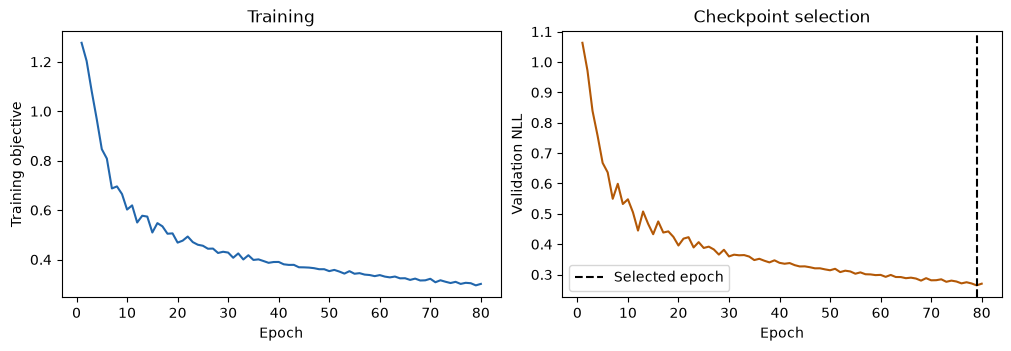

In [6]:
history, best_score, best_state, best_epoch = [], float("inf"), None, None
generator = torch.Generator().manual_seed(SEED)
stale_epochs = 0
for epoch in range(EPOCHS):
    model.train()
    permutation = torch.randperm(len(X_train), generator=generator)
    training_sum = 0.0
    for indices in permutation.split(BATCH_SIZE):
        optimizer.zero_grad(set_to_none=True)
        output = model(X_train[indices])
        loss = criterion(*output, Y_train[indices]) if TASK == "regression" else criterion(output, Y_train[indices], epoch)
        if not torch.isfinite(loss): raise RuntimeError("Nonfinite training loss; inspect data scaling and learning rate")
        loss.backward()
        optimizer.step()
        training_sum += loss.item()*len(indices)
    model.eval()
    with torch.no_grad():
        if TASK == "regression":
            mu, nu, alpha, beta = model(X_val)
            pred = torch.distributions.StudentT(2*alpha, mu, torch.sqrt(beta*(1+nu)/(nu*alpha)))
            validation_score = -pred.log_prob(Y_val).mean().item()
        else:
            p = model.predict(X_val)[0]
            validation_score = -torch.sum(Y_val*torch.log(p), dim=1).mean().item()
    history.append({"epoch": epoch+1, "train_objective": training_sum/len(X_train),
                    "validation_nll": validation_score})
    if validation_score < best_score - 1e-6:
        best_score, best_epoch = validation_score, epoch+1
        best_state = copy.deepcopy(model.state_dict())
        stale_epochs = 0
    else:
        stale_epochs += 1
    if stale_epochs >= PATIENCE:
        break
if best_state is None: raise RuntimeError("Training did not produce a finite validation score")
model.load_state_dict(best_state)
model.eval()
history = pd.DataFrame(history)
history.to_csv(OUTPUT_DIR/"training_history.csv", index=False)
print(f"Selected epoch {best_epoch} using validation NLL only.")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
axes[0].plot(history.epoch, history.train_objective, color="#2166ac")
axes[0].set(xlabel="Epoch", ylabel="Training objective", title="Training")
axes[1].plot(history.epoch, history.validation_nll, color="#b35806")
axes[1].axvline(best_epoch, color="black", linestyle="--", label="Selected epoch")
axes[1].set(xlabel="Epoch", ylabel="Validation NLL", title="Checkpoint selection")
axes[1].legend()
plt.show()

## Report untouched test results

In [7]:
# The model and all preprocessing are now frozen. Evaluate test outcomes here.
if TASK == "regression":
    parameters = tuple(value.detach().cpu().numpy()
                       for value in model.predict(X_test, return_uncertainties=False))
    evaluation = evaluate_nig(y_all[test_idx], parameters, y_scaler=y_scaler)
    metrics = evaluation["metrics"].copy()
    metrics.index = TARGET_COLUMNS
    display(metrics)
    display(evaluation["coverage"])
    metrics.to_csv(OUTPUT_DIR/"test_metrics.csv", index_label="target")
    evaluation["coverage"].to_csv(OUTPUT_DIR/"test_coverage.csv", index=False)
    prediction_table = pd.DataFrame({"row_position": test_idx})
    lower, upper = evaluation["intervals"][0.9]
    for j, name in enumerate(TARGET_COLUMNS):
        prediction_table[f"{name}_truth"] = y_all[test_idx, j]
        prediction_table[f"{name}_mean"] = evaluation["mean"][:, j]
        prediction_table[f"{name}_aleatoric_variance"] = evaluation["aleatoric"][:, j]
        prediction_table[f"{name}_epistemic_variance"] = evaluation["epistemic"][:, j]
        prediction_table[f"{name}_lower90"] = lower[:, j]
        prediction_table[f"{name}_upper90"] = upper[:, j]
else:
    probability, dst_mass, aleatoric, epistemic = [
        value.detach().cpu().numpy() for value in model.predict(X_test)]
    test_labels = label_encoder.transform(y_all[test_idx])
    evaluation = evaluate_classifier(test_labels, probability)
    display(pd.Series(evaluation["metrics"], name="test").to_frame())
    pd.Series(evaluation["metrics"]).to_csv(OUTPUT_DIR/"test_metrics.csv", header=["value"])
    prediction_table = pd.DataFrame({"row_position": test_idx, "truth": y_all[test_idx],
        "prediction": label_encoder.inverse_transform(probability.argmax(axis=1)),
        "dst_uncertainty_mass": dst_mass[:, 0],
        "aleatoric_variance_trace": aleatoric.sum(axis=1),
        "epistemic_variance_trace": epistemic.sum(axis=1)})
    for j, name in enumerate(label_encoder.classes_):
        prediction_table[f"p_{name}"] = probability[:, j]
prediction_table.to_csv(OUTPUT_DIR/"test_predictions.csv", index=False)

,test
accuracy,0.987500
log_loss,0.251774
brier,0.082284
ece,0.194406


## Visualise classification performance and uncertainty
The uncertainty comparison uses held-out outcomes only for evaluation. Dirichlet epistemic variance and Dempster–Shafer uncertainty mass are separate diagnostics.

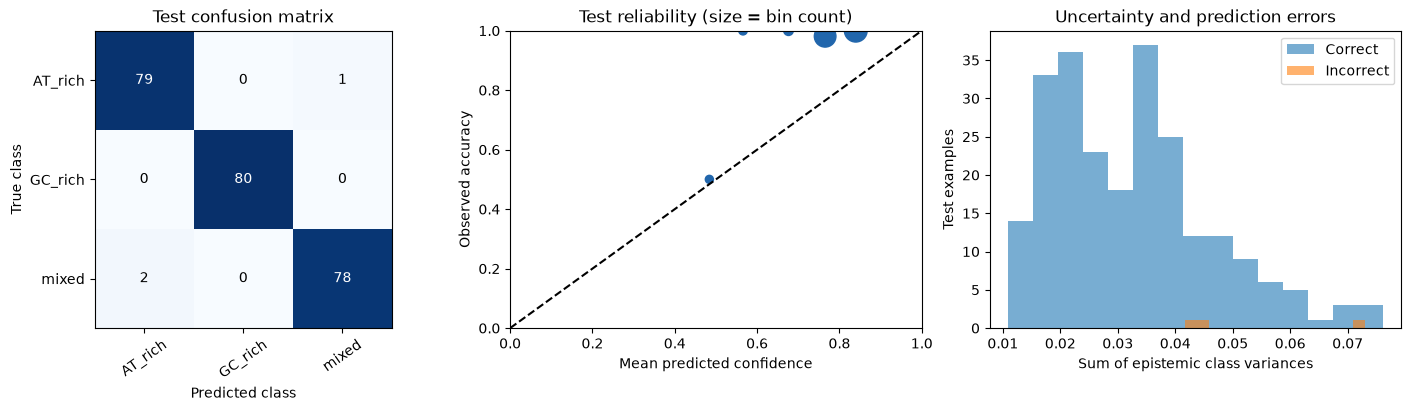

In [8]:
if TASK == "regression":
    target = 0  # Change to inspect another output; metrics above include every target.
    actual = y_all[test_idx, target]
    predicted = evaluation["mean"][:, target]
    lower, upper = evaluation["intervals"][0.9]
    order = np.argsort(predicted)
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
    axes[0,0].scatter(actual, predicted, s=20, alpha=.65, color="#2166ac")
    lo, hi = min(actual.min(), predicted.min()), max(actual.max(), predicted.max())
    axes[0,0].plot([lo, hi], [lo, hi], "k--")
    axes[0,0].set(xlabel="Observed target", ylabel="Predicted mean", title="Held-out test predictions")
    axes[0,1].fill_between(np.arange(len(order)), lower[order,target], upper[order,target],
                           color="#92c5de", alpha=.6, label="90% Student-t predictive interval")
    axes[0,1].plot(predicted[order], color="#2166ac", label="Predictive mean")
    axes[0,1].scatter(np.arange(len(order)), actual[order], s=8, color="#333333", alpha=.6, label="Observed")
    axes[0,1].set(xlabel="Test examples ordered by predicted mean", ylabel=TARGET_COLUMNS[target],
                  title="Predictive intervals")
    axes[0,1].legend(fontsize=8)
    calibration = evaluation["coverage"].query("target == @target")
    axes[1,0].plot(calibration.nominal, calibration.observed, "o-", color="#b35806", label="Observed coverage")
    axes[1,0].plot([0,1], [0,1], "k--", label="Ideal")
    axes[1,0].set(xlim=(0,1), ylim=(0,1), xlabel="Nominal coverage", ylabel="Test coverage",
                  title="Interval calibration")
    axes[1,0].legend()
    axes[1,1].scatter(predicted, np.sqrt(evaluation["aleatoric"][:,target]), s=15, alpha=.6,
                      label="Aleatoric SD", color="#2166ac")
    axes[1,1].scatter(predicted, np.sqrt(evaluation["epistemic"][:,target]), s=15, alpha=.6,
                      label="Epistemic SD", color="#b35806")
    axes[1,1].set(xlabel="Predicted mean", ylabel="Standard deviation (target units)",
                  title="Uncertainty components")
    axes[1,1].legend()
    fig.suptitle(f"Test evaluation: {TARGET_COLUMNS[target]}")
else:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    confusion = evaluation["confusion"]
    image = axes[0].imshow(confusion, cmap="Blues")
    for row in range(len(confusion)):
        for col in range(len(confusion)):
            axes[0].text(col,row,str(confusion[row,col]), ha="center", va="center",
                         color="white" if confusion[row,col] > confusion.max()/2 else "black")
    axes[0].set(xticks=range(n_classes), yticks=range(n_classes),
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_,
                xlabel="Predicted class", ylabel="True class", title="Test confusion matrix")
    axes[0].tick_params(axis="x", rotation=35)
    reliability = evaluation["reliability"].query("count > 0")
    axes[1].plot([0,1], [0,1], "k--")
    axes[1].scatter(reliability.confidence, reliability.accuracy,
                     s=30+2*reliability["count"], color="#2166ac")
    axes[1].set(xlim=(0,1), ylim=(0,1), xlabel="Mean predicted confidence", ylabel="Observed accuracy",
                title="Test reliability (size = bin count)")
    correct = probability.argmax(axis=1) == test_labels
    trace_epistemic = epistemic.sum(axis=1)
    if correct.any(): axes[2].hist(trace_epistemic[correct], bins=15, alpha=.6, label="Correct")
    if (~correct).any(): axes[2].hist(trace_epistemic[~correct], bins=15, alpha=.6, label="Incorrect")
    axes[2].set(xlabel="Sum of epistemic class variances", ylabel="Test examples",
                title="Uncertainty and prediction errors")
    axes[2].legend()
fig.savefig(OUTPUT_DIR/"test_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()

## Save the reproducible experiment

In [9]:
torch.save(model.state_dict(), OUTPUT_DIR/"model.pt")
joblib.dump({"x_scaler": x_scaler, "y_scaler": y_scaler, "label_encoder": label_encoder},
            OUTPUT_DIR/"preprocessing.joblib")
metadata = {"task": TASK, "features": FEATURE_COLUMNS, "targets": TARGET_COLUMNS,
            "split_strategy": SPLIT_STRATEGY, "seed": SEED, "best_epoch": best_epoch,
            "model_kwargs": model_kwargs, "torch": torch.__version__, "numpy": np.__version__,
            "training": {"optimizer": "Adam", "learning_rate": LEARNING_RATE,
                "batch_size": BATCH_SIZE, "max_epochs": EPOCHS, "patience": PATIENCE,
                "test_fraction": TEST_FRACTION, "validation_fraction": VALIDATION_FRACTION,
                "group_column": GROUP_COLUMN, "time_column": TIME_COLUMN,
                "regression_loss": "LipschitzMSELoss", "regression_coef": 0.01,
                "classification_loss": "EDLDigammaLoss", "annealing_step": 20,
                "classification_initial_head_bias": 1.0},
            "python": platform.python_version(), "miles_guess": version("miles-guess")}
(OUTPUT_DIR/"metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved model, fitted preprocessing, split assignments, metrics, and test predictions to", OUTPUT_DIR.resolve())

Saved model, fitted preprocessing, split assignments, metrics, and test predictions to /workspace/scratch/d7d34632ac75/miles-guess/notebooks/outputs/dna_sequence_demo


## Predict new sequences
Use exactly the same feature construction and saved training scaler. For your own CSV datasets, see evidential_learning_your_data.ipynb.

In [10]:
new_sequences = ["ACGT"*12, "AATT"*12, "GGCC"*12]
new_features = np.array([[sequence.count(base)/len(sequence) for base in bases] for sequence in new_sequences])
new_inputs = torch.tensor(x_scaler.transform(new_features), dtype=torch.float32)
new_probability = model.predict(new_inputs)[0].cpu().numpy()
display(pd.DataFrame(new_probability, columns=label_encoder.classes_))

,AT_rich,GC_rich,mixed
0,0.202684,0.202684,0.594632
1,0.870599,0.064701,0.064701
2,0.055136,0.889727,0.055136
